# 07 · Análisis del monitoreo, ética y resultado de negocio

Analiza la simulación de producción que ejecutó Kestra (`produccion_lotes.yml`), lote por lote:

1. Métricas de sistema, datos, deriva y modelo.
2. Alertas y diagnóstico del tipo de deriva.
3. Reentrenamientos: comparación champion vs. challenger y decisión.
4. Ética operativa: desempeño por subgrupo (`estado_operacion`).
5. Resultado de negocio: el modelo frente a la regla actual, con el efecto del reentrenamiento.
6. Exportación de la evidencia a `docs/` en CSV.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import pandas as pd
from sklearn.metrics import average_precision_score
from src.datos import leer_tabla
from src.lotes import INICIO_DERIVA

UMBRAL_PR_AUC = 0.415
CAPACIDAD = 600

monitoreo = leer_tabla("MONITOREO")
alertas = leer_tabla("ALERTAS")
predicciones = leer_tabla("PREDICCIONES")
lotes = leer_tabla("LOTES")
monitoreo["variable"] = monitoreo["variable"].fillna("")
print(f"Lotes puntuados: {predicciones['fecha_lote'].nunique()} | predicciones: {len(predicciones):,} | "
      f"metricas: {len(monitoreo):,} | alertas: {len(alertas)}")

Lotes puntuados: 18 | predicciones: 57,506 | metricas: 1,394 | alertas: 36


## 1. Métricas lote por lote

Una fila por lote. Las de **sistema, datos y deriva** se calculan el mismo día; las de **desempeño** (PR-AUC y pagos), cuando llega el target, 7 días después.

In [2]:
def por_lote(tipo, metricas, variable=""):
    datos = monitoreo[(monitoreo["tipo"] == tipo) & monitoreo["metrica"].isin(metricas)
                      & (monitoreo["variable"] == variable)]
    return datos.pivot_table(index="fecha_lote", columns="metrica", values="valor")

psi = monitoreo[monitoreo["metrica"] == "psi"].pivot_table(index="fecha_lote", columns="variable", values="valor")
tabla = pd.concat([
    por_lote("sistema", ["volumen", "latencia_p50_ms", "latencia_p95_ms", "tasa_4xx", "tasa_5xx"]),
    psi[["dias_mora"]].rename(columns={"dias_mora": "psi_dias_mora"}),
    psi.drop(columns="dias_mora").max(axis=1).rename("psi_max_otras"),
    por_lote("modelo", ["probabilidad_media", "tasa_gestionar_lista", "tasa_gestionar_api"]),
    por_lote("desempeno", ["pr_auc", "pagos_capturados", "pagos_linea_base", "pagos_totales"]),
], axis=1)
tabla["alterado"] = (tabla.index >= INICIO_DERIVA).astype(int)
tabla.round(3)

,latencia_p50_ms,latencia_p95_ms,tasa_4xx,tasa_5xx,volumen,psi_dias_mora,psi_max_otras,probabilidad_media,tasa_gestionar_api,tasa_gestionar_lista,pagos_capturados,pagos_linea_base,pagos_totales,pr_auc,alterado
fecha_lote,,,,,,,,,,,,,,,
2026-10-14,19.44,33.488,0.000,0.0,2574.0,0.025,0.020,0.340,0.183,0.233,249.0,124.0,465.0,0.582,0
2026-10-15,19.41,32.117,0.000,0.0,2507.0,0.067,0.034,0.333,0.184,0.239,242.0,127.0,442.0,0.573,0
2026-10-16,19.38,32.375,0.000,0.0,2419.0,0.187,0.039,0.320,0.172,0.248,219.0,119.0,389.0,0.512,0
2026-10-17,20.30,36.633,0.000,0.0,3970.0,0.068,0.254,0.480,0.336,0.151,301.0,202.0,1115.0,0.554,0
2026-10-18,20.11,34.150,0.001,0.0,3970.0,6.091,0.254,0.230,0.046,0.151,263.0,202.0,1114.0,0.385,1
2026-10-19,19.80,41.258,0.001,0.0,3849.0,6.050,0.239,0.239,0.066,0.156,295.0,200.0,1029.0,0.426,1
2026-10-20,19.56,33.050,0.001,0.0,3462.0,5.899,0.186,0.215,0.044,0.174,242.0,166.0,701.0,0.337,1
2026-10-21,19.47,32.408,0.001,0.0,3285.0,5.821,0.167,0.211,0.052,0.183,194.0,147.0,609.0,0.320,1
2026-10-22,19.51,33.183,0.001,0.0,3180.0,5.777,0.162,0.206,0.048,0.189,219.0,149.0,587.0,0.363,1


## 2. Gráficos lote por lote

La línea vertical punteada marca el inicio de la deriva inducida; las rojas, los lotes cuya evaluación disparó un reentrenamiento.

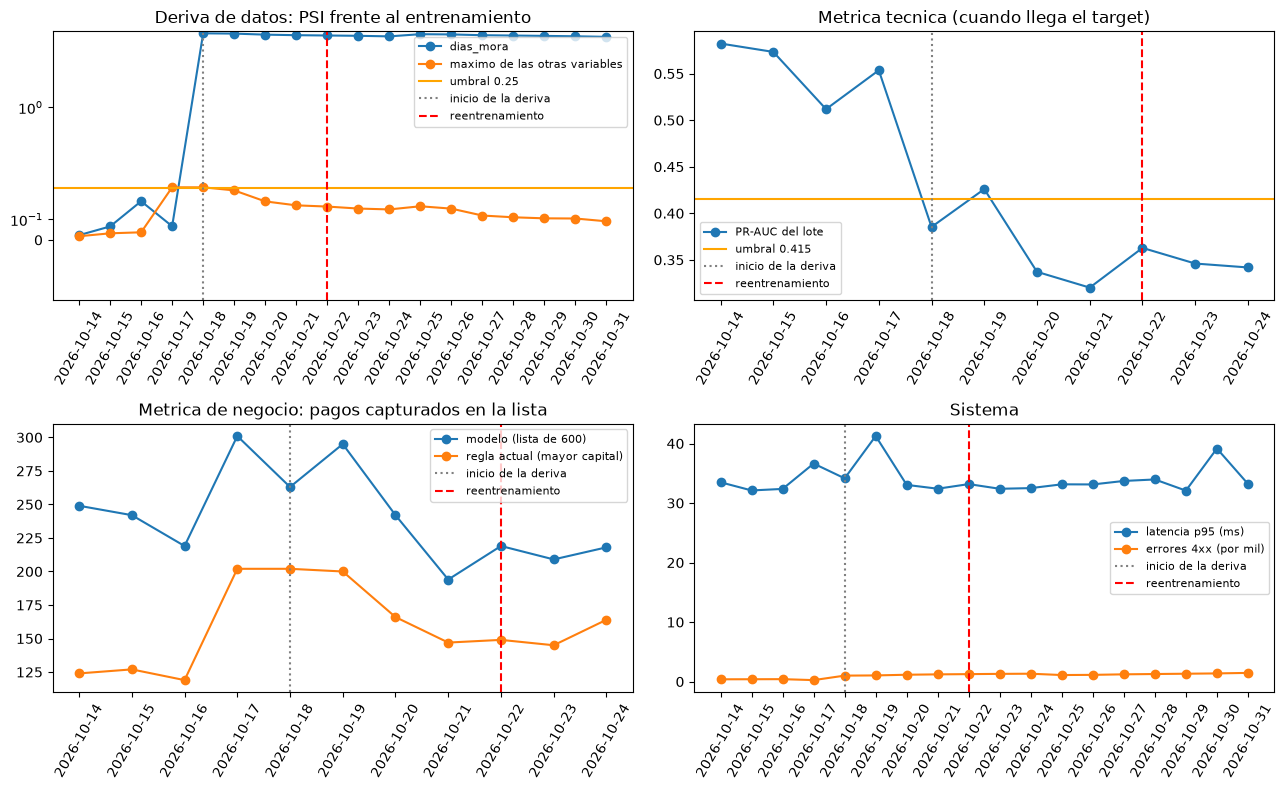

In [3]:
reentrenamientos = alertas[alertas["metrica"] == "reentrenamiento"]["fecha_lote"].sort_values().tolist()
fechas = tabla.index.tolist()

def marcar(eje):
    eje.axvline(fechas.index(INICIO_DERIVA), color="gray", linestyle=":", label="inicio de la deriva")
    for fecha in reentrenamientos:
        eje.axvline(fechas.index(fecha), color="red", linestyle="--", label="reentrenamiento")

fig, ejes = plt.subplots(2, 2, figsize=(13, 8))
ejes[0, 0].plot(fechas, tabla["psi_dias_mora"], marker="o", label="dias_mora")
ejes[0, 0].plot(fechas, tabla["psi_max_otras"], marker="o", label="maximo de las otras variables")
ejes[0, 0].axhline(0.25, color="orange", label="umbral 0.25")
ejes[0, 0].set_yscale("symlog", linthresh=0.5)
ejes[0, 0].set_title("Deriva de datos: PSI frente al entrenamiento")

ejes[0, 1].plot(fechas, tabla["pr_auc"], marker="o", label="PR-AUC del lote")
ejes[0, 1].axhline(UMBRAL_PR_AUC, color="orange", label=f"umbral {UMBRAL_PR_AUC}")
ejes[0, 1].set_title("Metrica tecnica (cuando llega el target)")

ejes[1, 0].plot(fechas, tabla["pagos_capturados"], marker="o", label="modelo (lista de 600)")
ejes[1, 0].plot(fechas, tabla["pagos_linea_base"], marker="o", label="regla actual (mayor capital)")
ejes[1, 0].set_title("Metrica de negocio: pagos capturados en la lista")

ejes[1, 1].plot(fechas, tabla["latencia_p95_ms"], marker="o", label="latencia p95 (ms)")
ejes[1, 1].plot(fechas, tabla["tasa_4xx"] * 1000, marker="o", label="errores 4xx (por mil)")
ejes[1, 1].set_title("Sistema")

for eje in ejes.flat:
    marcar(eje)
    eje.tick_params(axis="x", rotation=60)
    manejadores, etiquetas = eje.get_legend_handles_labels()
    unicos = dict(zip(etiquetas, manejadores))
    eje.legend(unicos.values(), unicos.keys(), fontsize=8)
plt.tight_layout()
plt.savefig("../docs/figuras/monitoreo_lotes.png", bbox_inches="tight")
plt.show()

## 3. Alertas y diagnóstico

Registro de alertas y, para cada lote evaluado, el diagnóstico de la tabla del PDF: si cambian las entradas (PSI > 0.25 en alguna variable) y si cae el desempeño (PR-AUC < 0.415).

In [4]:
alertas[["fecha_proceso", "fecha_lote", "metrica", "variable", "valor", "umbral", "severidad", "recibe", "accion"]] \
    .sort_values(["fecha_proceso", "severidad"]).round(3)

,fecha_proceso,fecha_lote,metrica,variable,valor,umbral,severidad,recibe,accion
0,2026-10-16,2026-10-16,psi,dias_mora,0.187,0.100,Media,Equipo de datos,Vigilar en los siguientes lotes
1,2026-10-17,2026-10-17,psi,dia_pago,0.254,0.250,Alta,Equipo de datos,Revisar la fuente; reentrenar solo si cae el d...
2,2026-10-18,2026-10-18,psi,dias_mora,6.091,0.250,Alta,Equipo de datos,Revisar la fuente; reentrenar solo si cae el d...
3,2026-10-18,2026-10-18,psi,dia_pago,0.254,0.250,Alta,Equipo de datos,Revisar la fuente; reentrenar solo si cae el d...
4,2026-10-19,2026-10-19,psi,dias_mora,6.050,0.250,Alta,Equipo de datos,Revisar la fuente; reentrenar solo si cae el d...
5,2026-10-19,2026-10-19,psi,dia_pago,0.239,0.100,Media,Equipo de datos,Vigilar en los siguientes lotes
6,2026-10-20,2026-10-20,psi,dias_mora,5.899,0.250,Alta,Equipo de datos,Revisar la fuente; reentrenar solo si cae el d...
7,2026-10-20,2026-10-20,psi,dia_pago,0.186,0.100,Media,Equipo de datos,Vigilar en los siguientes lotes
8,2026-10-21,2026-10-21,psi,dias_mora,5.821,0.250,Alta,Equipo de datos,Revisar la fuente; reentrenar solo si cae el d...
9,2026-10-21,2026-10-21,psi,dia_pago,0.167,0.100,Media,Equipo de datos,Vigilar en los siguientes lotes


In [5]:
diagnostico = tabla.dropna(subset=["pr_auc"])[["psi_dias_mora", "psi_max_otras", "pr_auc"]].copy()
diagnostico["entradas"] = (diagnostico[["psi_dias_mora", "psi_max_otras"]].max(axis=1) > 0.25).map(
    {True: "cambian", False: "estables"})
diagnostico["desempeno"] = (diagnostico["pr_auc"] < UMBRAL_PR_AUC).map({True: "cae", False: "se mantiene"})
casos = {("cambian", "se mantiene"): "Deriva de datos sin impacto",
         ("cambian", "cae"): "Deriva de datos con impacto",
         ("estables", "cae"): "Deriva conceptual",
         ("estables", "se mantiene"): "Sin deriva"}
diagnostico["diagnostico"] = [casos[(e, d)] for e, d in zip(diagnostico["entradas"], diagnostico["desempeno"])]
diagnostico.round(3)

,psi_dias_mora,psi_max_otras,pr_auc,entradas,desempeno,diagnostico
fecha_lote,,,,,,
2026-10-14,0.025,0.020,0.582,estables,se mantiene,Sin deriva
2026-10-15,0.067,0.034,0.573,estables,se mantiene,Sin deriva
2026-10-16,0.187,0.039,0.512,estables,se mantiene,Sin deriva
2026-10-17,0.068,0.254,0.554,cambian,se mantiene,Deriva de datos sin impacto
2026-10-18,6.091,0.254,0.385,cambian,cae,Deriva de datos con impacto
2026-10-19,6.050,0.239,0.426,cambian,se mantiene,Deriva de datos sin impacto
2026-10-20,5.899,0.186,0.337,cambian,cae,Deriva de datos con impacto
2026-10-21,5.821,0.167,0.320,cambian,cae,Deriva de datos con impacto
2026-10-22,5.777,0.162,0.363,cambian,cae,Deriva de datos con impacto


## 4. Reentrenamientos

Corridas de MLflow con `fase = reentrenamiento`: motivo del disparo, comparación champion vs. challenger en el lote etiquetado más reciente, recomendación de la regla de promoción y decisión humana.

In [6]:
mlflow.set_experiment("priorizacion-cartera")
corridas = mlflow.search_runs(experiment_names=["priorizacion-cartera"])
reent = corridas[corridas["tags.fase"] == "reentrenamiento"]
columnas = ["run_id", "params.fecha_proceso", "params.lote_evaluacion", "params.version_champion",
            "metrics.pr_auc_champion", "metrics.pr_auc_challenger", "metrics.pagos_champion",
            "metrics.pagos_challenger", "tags.recomendacion", "tags.decision", "tags.comentario", "tags.motivo"]
reent[[c for c in columnas if c in reent.columns]].round(3)

,run_id,params.fecha_proceso,params.lote_evaluacion,params.version_champion,metrics.pr_auc_champion,metrics.pr_auc_challenger,metrics.pagos_champion,metrics.pagos_challenger,tags.recomendacion,tags.decision,tags.comentario,tags.motivo
0,36ef9880d7ac4f0ab55e99266c92f60d,2026-10-29,2026-10-22,1,0.363,0.57,219.0,263.0,promover,aprobado,Aprobado como medida temporal: mejora la lista...,PR-AUC bajo 0.415 (promedio de la CV menos 2 d...


## 5. Ética operativa: desempeño por subgrupo

Subgrupo: `estado_operacion` (VENCIDO = 1 a 30 días de mora; NON ACCRUAL = más de 30; CASTIGADA). Se usan los lotes **sin alterar y con target** (14 al 17 de octubre), para que la deriva inducida no mezcle el análisis.

In [7]:
normales = predicciones[(predicciones["codigo_http"] == 200) & (predicciones["fecha_lote"] < INICIO_DERIVA)].merge(
    lotes[["numero_operacion", "fecha_lote", "estado_operacion", "paga_7d"]], on=["numero_operacion", "fecha_lote"])
normales = normales.dropna(subset=["paga_7d"])

def resumen(grupo):
    return pd.Series({
        "creditos": len(grupo),
        "tasa_pago_real": grupo["paga_7d"].mean(),
        "pr_auc": average_precision_score(grupo["paga_7d"], grupo["probabilidad"]),
        "tasa_en_lista": grupo["en_lista"].mean(),
        "pagos_capturados_%": ((grupo["en_lista"] == 1) & (grupo["paga_7d"] == 1)).sum() / grupo["paga_7d"].sum() * 100,
    })

subgrupos = normales.groupby("estado_operacion").apply(resumen, include_groups=False)
subgrupos.round(3)

/workspaces/pset4/proyecto_final/.venv/lib/python3.12/site-packages/sklearn/metrics/_ranking.py:1030: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/tmp/ipykernel_127108/3633164215.py:11: RuntimeWarning: invalid value encountered in scalar divide
  "pagos_capturados_%": ((grupo["en_lista"] == 1) & (grupo["paga_7d"] == 1)).sum() / grupo["paga_7d"].sum() * 100,


,creditos,tasa_pago_real,pr_auc,tasa_en_lista,pagos_capturados_%
estado_operacion,,,,,
CASTIGADA,568.0,0.000,-0.000,0.000,NaN
NON ACCRUAL,6106.0,0.086,0.459,0.076,31.879
VENCIDO,4792.0,0.393,0.583,0.404,44.745


## 6. Resultado de negocio

Pagos capturados en la lista de 600 por lote: el modelo que estaba en producción frente a la regla actual (mayor capital insoluto primero).

**"No hacer nada" no aplica:** el call center gestiona todos los días; la alternativa real al modelo es la regla del jefe de cobranzas, aproximada por "mayor capital primero".

**Efecto del reentrenamiento:** el challenger aprobado no puntuó lotes con target en la simulación (el target de los últimos lotes llega después de octubre). Por eso su efecto se mide de forma retrospectiva sobre los lotes etiquetados que no vio en entrenamiento.

In [8]:
negocio = tabla.dropna(subset=["pagos_capturados"])[["pagos_capturados", "pagos_linea_base", "pagos_totales"]].copy()
negocio["diferencia"] = negocio["pagos_capturados"] - negocio["pagos_linea_base"]
negocio["mejora_%"] = negocio["diferencia"] / negocio["pagos_linea_base"] * 100
negocio["alterado"] = (negocio.index >= INICIO_DERIVA).astype(int)
print("Total de pagos capturados: modelo", int(negocio["pagos_capturados"].sum()),
      "| regla actual", int(negocio["pagos_linea_base"].sum()))
print("Lotes sin alterar: mejora promedio",
      round(negocio.loc[negocio["alterado"] == 0, "mejora_%"].mean(), 1), "%")
print("Lotes con deriva: mejora promedio",
      round(negocio.loc[negocio["alterado"] == 1, "mejora_%"].mean(), 1), "%")
negocio.round(1)

Total de pagos capturados: modelo 2651 | regla actual 1745
Lotes sin alterar: mejora promedio 81.1 %
Lotes con deriva: mejora promedio 39.9 %


,pagos_capturados,pagos_linea_base,pagos_totales,diferencia,mejora_%,alterado
fecha_lote,,,,,,
2026-10-14,249.0,124.0,465.0,125.0,100.8,0
2026-10-15,242.0,127.0,442.0,115.0,90.6,0
2026-10-16,219.0,119.0,389.0,100.0,84.0,0
2026-10-17,301.0,202.0,1115.0,99.0,49.0,0
2026-10-18,263.0,202.0,1114.0,61.0,30.2,1
2026-10-19,295.0,200.0,1029.0,95.0,47.5,1
2026-10-20,242.0,166.0,701.0,76.0,45.8,1
2026-10-21,194.0,147.0,609.0,47.0,32.0,1
2026-10-22,219.0,149.0,587.0,70.0,47.0,1


In [9]:
from mlflow import MlflowClient

cliente = MlflowClient()
aprobadas = reent[reent.get("tags.decision", pd.Series(dtype=str)) == "aprobado"]
COLUMNAS = [c for c in lotes.columns if c not in ("numero_operacion", "fecha_lote", "paga_7d", "alterado")]

def pagos_en_lista(modelo, lote):
    probabilidad = modelo.predict_proba(lote[COLUMNAS].assign(gestionado_7d=1))[:, 1]
    puntaje = pd.Series(probabilidad * lote["capital_insoluto"].to_numpy())
    en_lista = puntaje.rank(ascending=False, method="first") <= CAPACIDAD
    return int((en_lista.to_numpy() & (lote["paga_7d"].to_numpy() == 1)).sum())

if len(aprobadas):
    fila = aprobadas.sort_values("params.fecha_proceso").iloc[0]
    version_nueva = [v.version for v in cliente.search_model_versions(f"run_id='{fila['run_id']}'")][0]
    anterior = mlflow.sklearn.load_model(f"models:/priorizacion-cartera-modelo/{fila['params.version_champion']}")
    nuevo = mlflow.sklearn.load_model(f"models:/priorizacion-cartera-modelo/{version_nueva}")
    no_vistos = lotes[lotes["paga_7d"].notna() & (lotes["fecha_lote"] > fila["params.lote_evaluacion"])]
    efecto = pd.DataFrame({fecha: {"champion_anterior": pagos_en_lista(anterior, lote),
                                    f"reentrenado_v{version_nueva}": pagos_en_lista(nuevo, lote)}
                           for fecha, lote in no_vistos.groupby("fecha_lote")}).T
    print(f"Efecto del reentrenamiento aprobado (version {version_nueva}) en lotes que no vio:")
    display(efecto)
else:
    print("Ningun challenger fue aprobado: el champion no cambio durante la simulacion.")

Efecto del reentrenamiento aprobado (version 3) en lotes que no vio:


,champion_anterior,reentrenado_v3
2026-10-23,209,242
2026-10-24,218,278


## 7. Exportar la evidencia a `docs/`

Tablas `PREDICCIONES`, `MONITOREO` y `ALERTAS`, todas las corridas de MLflow (incluidas las de reentrenamiento) y, por separado, las de reentrenamiento.

In [10]:
predicciones.to_csv("../docs/predicciones.csv", index=False)
monitoreo.to_csv("../docs/monitoreo.csv", index=False)
alertas.to_csv("../docs/alertas.csv", index=False)
corridas.to_csv("../docs/corridas.csv", index=False)
reent.to_csv("../docs/reentrenamientos.csv", index=False)
print(f"predicciones: {len(predicciones):,} | monitoreo: {len(monitoreo):,} | alertas: {len(alertas)} | "
      f"corridas: {len(corridas)} | reentrenamientos: {len(reent)}")

predicciones: 57,506 | monitoreo: 1,394 | alertas: 36 | corridas: 102 | reentrenamientos: 1
